# 14 - NMR Petrophysics

**Part B - Petrophys Curriculum**

Nuclear Magnetic Resonance (NMR) logging measures the relaxation of hydrogen
protons in the pore fluid. Unlike density, neutron or sonic tools, the NMR
response is **independent of the rock matrix** - it "sees" only the fluids in
the pore space. That single property makes NMR the most direct downhole
measurement of porosity, pore-size distribution, bound versus movable fluid,
and (through empirical models) permeability.

This lesson works the `petrophys.interpretation.nmr` toolkit on a **real CMR log**: the
Schlumberger CMR summary deliverable from **Daydream 1** (QGC, ATP 645, Bowen
Basin, Queensland) - the same publicly released well whose FMI drives
lesson 16. Two depth sections ship with the package; we use the deep one
(3755-4145 m) and leave the shallow one for the exercises.

The deliverable is a **summary** export: total and free-fluid porosity, the T2
cutoff and the vendor permeabilities. It does **not** contain the per-depth T2
distribution (the T2 bins), so this lesson works with the summary curves and
shows how the library refuses bin-based products rather than inventing them.

## Learning goals

By the end of this lesson you will be able to:

- Load a real CMR summary deliverable into `NMRData` with `from_las`
  (mnemonic aliases, automatic v/v-to-pu conversion, `MBVI` derived as
  `MPHI - MFFI`).
- Read the porosity partition (bound vs free fluid) and **Swirr** from real
  curves, at the T2 cutoff recorded in the file itself.
- Compute **Timur-Coates permeability** from the summary curves and validate
  it against the vendor's own `KTIM`, recovering the vendor's constant with
  `calibrate_coates`.
- Know which products need **T2 bins** (T2 distribution, T2lm, SDR
  permeability, pore size) and how `NMRData` refuses rather than guesses when
  they are absent.

## Why this matters (the physics)

After a polarizing pulse, hydrogen protons in the pore fluid relax back to
equilibrium with a **transverse relaxation time $T_2$**. In a water-wet rock the
dominant mechanism is *surface relaxation*, and to first order

$$\frac{1}{T_2} \approx \rho_2\,\frac{S}{V},$$

where $\rho_2$ is the surface relaxivity and $S/V$ is the pore surface-to-volume
ratio. Small pores have a **large** $S/V$ and relax **fast** (short $T_2$); large
pores relax slowly (long $T_2$). So the measured **T2 distribution is a proxy for
the pore-size distribution**:

- **Short $T_2$** -> tiny/clay-bound and capillary-bound water -> **irreducible** (BVI).
- **Long $T_2$** -> large pores holding **movable** (free) fluid (FFI).

A single **T2 cutoff** separates the two. The total area under the T2
distribution is the **NMR porosity (MPHI)** - matrix-independent, hence a
gold-standard porosity. A summary export such as ours keeps the results of
that split (total porosity, free fluid, the cutoff used) but not the
distribution itself.

### Prerequisites
This lesson assumes you have worked through the Part A porosity (04) and
permeability (08) lessons. Basic familiarity with porosity units (fractions
vs porosity units, "pu" = percent) is helpful.

In [1]:
%matplotlib inline
from petrophys.visualization import use_plot_style
use_plot_style()
import textwrap

import numpy as np
import matplotlib.pyplot as plt

import petrophys as pp
from petrophys.interpretation.nmr import NMRData

print("petrophys", pp.__version__)

petrophys 3.0.0


## 1. Load the real CMR deliverable

The bundled `daydream1_cmr.las` is the service company's standard CMR summary
export: total porosity `TCMR`, free fluid `CMFF`, 3-ms porosity `CMRP_3MS`,
the vendor's SDR and Timur permeabilities `KSDR` / `KTIM`, the `T2CUTOFF`
actually applied downhole, plus GR and calipers for QC.

`NMRData.from_las` does the housekeeping:

- resolves CMR mnemonics onto the MRIL-style names the container uses
  (`TCMR -> MPHI`, `CMFF -> MFFI`),
- converts fractional (v/v) porosities to **pu**,
- derives `MBVI = MPHI - MFFI` when no bound-fluid curve is present,
- reads the T2 cutoff from the `T2CUTOFF` curve,
- stores the vendor permeabilities and every remaining curve
  (`stored_permeability`, `extra_curves`).

One quirk of the file: it is written deepest-first (decreasing depth). That is
a valid, monotonic depth index, so it loads without a warning, and per-sample
NMR arithmetic is unaffected. Just remember that the first row is the deepest
sample (the export table in section 5 shows it).

In [2]:
nmr = NMRData.from_las(
    pp.sample("daydream1_cmr"),
    mphi_mnemonic="TCMR", mffi_mnemonic="CMFF",
)

print("samples          :", nmr.n_samples)
print("depth            : %.1f - %.1f m" % (nmr.top, nmr.bottom))
print("T2 cutoff        : %.0f ms (from the T2CUTOFF curve)" % nmr.t2_cutoff)
print("has_bins / has_t2lm:", nmr.has_bins, "/", nmr.has_t2lm)
print("MPHI (pu)        : median %.2f, max %.1f" % (np.nanmedian(nmr.mphi), np.nanmax(nmr.mphi)))
print("vendor perms     :", sorted(nmr.stored_permeability))
print("extra curves     :", sorted(nmr.extra_curves))

samples          : 15606
depth            : 3755.0 - 4145.1 m
T2 cutoff        : 33 ms (from the T2CUTOFF curve)
has_bins / has_t2lm: False / False
MPHI (pu)        : median 6.63, max 72.2
vendor perms     : ['KSDR', 'KTIM']
extra curves     : ['BS', 'CDF', 'CMRP_3MS', 'CMR_TEMP', 'GR_EDTC', 'HD1_PPC1', 'HD2_PPC1', 'KSDR', 'KTIM', 'STIT', 'T2CUTOFF', 'TENS']


## 2. Summary curves vs T2 bins

This deliverable carries **summary curves only** - the per-depth T2 bin
amplitudes (the full T2 distribution) were never exported to LAS. That rules
out the bin-based products:

- the **T2 distribution** itself and its **log-mean T2lm**,
- **SDR permeability** ($k = C\,\phi^4\,T2_{lm}^2$), which needs T2lm,
- **pore-size** estimates from surface relaxivity,
- re-splitting BVI/FFI at a *different* cutoff (the vendor's split at 33 ms is
  baked into `CMFF`).

When bin data exist, `NMRData` ingests them via `from_csv` / `bin_mnemonics`
(MRIL `P1...P8` or `T2B01...T2B08`). We do not fabricate bins to demo those
methods - and the container is honest when asked for something the data cannot
support:

In [3]:
try:
    nmr.permeability_sdr(prefer_stored=False)
except ValueError as e:
    print("permeability_sdr(prefer_stored=False) raises:")
    print("  ValueError:", e)

# The vendor's KSDR - computed downhole from the full T2 distribution - is
# still available, because prefer_stored defaults to True:
ksdr = nmr.permeability_sdr()
print()
print("nmr.permeability_sdr() returns the stored vendor KSDR: median %.4f mD"
      % np.nanmedian(ksdr))

permeability_sdr(prefer_stored=False) raises:
  ValueError: T2lm requires either T2 bin data (P1–P8) or a T2LM curve loaded from the LAS file (pass t2lm_mnemonic='T2LM' to from_las).

nmr.permeability_sdr() returns the stored vendor KSDR: median 0.0009 mD


### 2b. The T2 distribution and a T2 waterfall

> **Coming with real data.** This section will plot the T2 distribution at single depths and as a depth-by-T2 waterfall, the pictures NMR interpretation starts from.
>
> Craig Phillips's eight-bin teaching example is now available as `pp.sample("phillips_nmr_bins")`; see the [dataset notes](https://github.com/sambalshikhar/petrophys/blob/main/src/petrophys/datasets/phillips/README.md) for the explicit T2 axis and loading example. Its source well/acquisition are not identified, so this field-data section still needs a traceable CMR, MRIL or MR Scanner distribution. The example is separate from Daydream.


## 3. Porosity partition and Swirr

The deep section sits in tight Permian coal measures, and the real curves say
so: the median total NMR porosity printed below is low, and nearly all of it is
**bound fluid** (compare the `MFFI` and `MBVI` medians). The NMR irreducible
saturation $S_{wirr} = MBVI/MPHI$ is therefore very high across the section.

MPHI  (pu): median 6.63
MFFI  (pu): median 0.49
MBVI  (pu): median 6.01  (derived MPHI - MFFI)
Swirr     : median 0.92


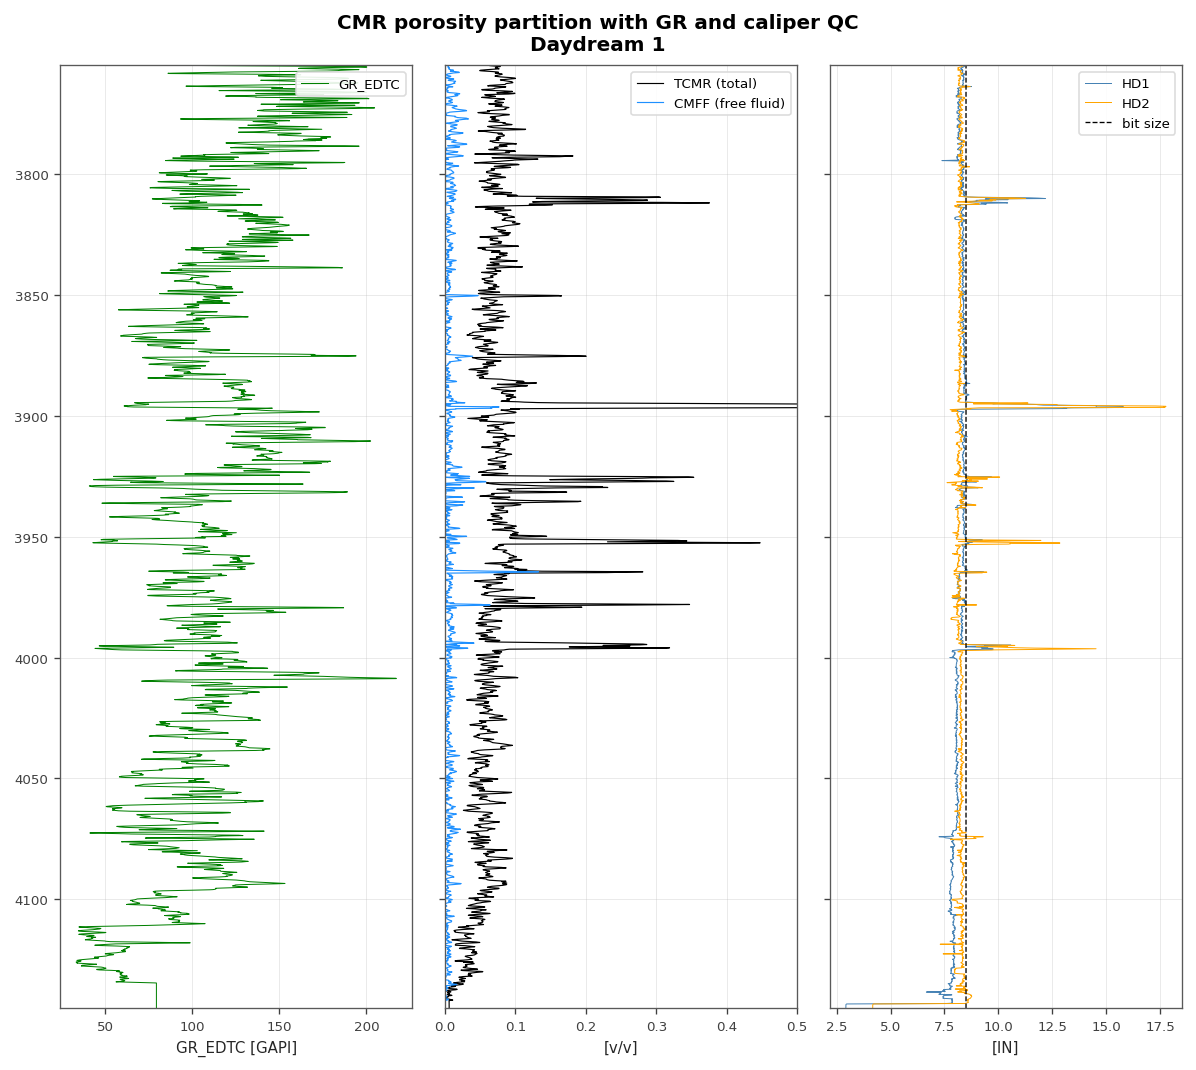

In [4]:
swirr = nmr.swirr_nmr()
print("MPHI  (pu): median %.2f" % np.nanmedian(nmr.mphi))
print("MFFI  (pu): median %.2f" % np.nanmedian(nmr.mffi))
print("MBVI  (pu): median %.2f  (derived MPHI - MFFI)" % np.nanmedian(nmr.mbvi))
print("Swirr     : median %.2f" % np.nanmedian(swirr))

from petrophys.visualization import LogPlot

w = pp.read(pp.sample("daydream1_cmr"))
lp = LogPlot(w, figsize=(10, 9))
lp.create_figure(n_tracks=3)
lp.add_curve(0, "GR_EDTC", color="green", linewidth=0.6, label="GR_EDTC")
lp.add_curve(1, "TCMR", color="black", linewidth=0.7, label="TCMR (total)", xlim=(0, 0.5))
lp.add_curve(1, "CMFF", color="dodgerblue", linewidth=0.7, label="CMFF (free fluid)")
lp.add_curve(2, "HD1_PPC1", color="steelblue", linewidth=0.6, label="HD1")
lp.add_curve(2, "HD2_PPC1", color="orange", linewidth=0.6, label="HD2")
lp.add_curve(2, "BS", color="black", linewidth=0.8, linestyle="--", label="bit size")
lp.set_depth_range(top=3755, bottom=4145)
lp.add_title("CMR porosity partition with GR and caliper QC")
lp.show()

### QC: the high-TCMR spikes

`TCMR` spikes above 30 pu in thin streaks. Two real causes coexist here, and
the companion curves separate them:

- **Coal.** The spikes sit at *lower* GR than the section average - coal is
  organically bound hydrogen with a large NMR response and low radioactivity.
- **Washout.** A large share of the spike samples also show the caliper more
  than an inch over bit size (the count is printed below), where borehole
  fluid inflates the reading.

Always read an NMR porosity spike against GR and caliper before calling it
reservoir.

In [5]:
hd = nmr.extra_curves["HD1_PPC1"]
bit = nmr.extra_curves["BS"]
gr = nmr.extra_curves["GR_EDTC"]

hi = np.isfinite(nmr.mphi) & (nmr.mphi > 30)
wash = np.isfinite(hd) & np.isfinite(bit) & (hd > bit + 1.0)

print("samples with TCMR > 30 pu     : %d" % hi.sum())
print("  ... of those in washout     : %d  (HD1 > BS + 1 in)" % (hi & wash).sum())
print("GR at the spikes vs overall   : median %.0f vs %.0f API"
      % (np.nanmedian(gr[hi]), np.nanmedian(gr)))

samples with TCMR > 30 pu     : 194
  ... of those in washout     : 95  (HD1 > BS + 1 in)
GR at the spikes vs overall   : median 70 vs 107 API


### 3b. T2 log-mean and the T2 cutoff from bins

> **Coming with real data.** This section will compute the T2 log-mean and the bound/free-fluid split (BVI/FFI) directly from the distribution, and show how moving the cutoff from 33 ms (clastics) to 92 ms (carbonates) changes both.
>
> `NMRData.bvi_from_bins` and `ffi_from_bins` split at the container's `t2_cutoff`, 33 ms by default (`T2_CUTOFF_CLASTIC`; `T2_CUTOFF_CARBONATE` is 92 ms; Coates, Xiao and Prammer, 1999), or at a `cutoff_ms` you pass. The bin that straddles the cutoff is split by its log-T2 width (`t2_fraction_below_cutoff`): with centres of 4-512 ms, 33 ms falls inside the 32 ms bin, so part of that bin counts as bound fluid and the rest as free fluid. `partial_bins=False` counts whole bins by their centre instead.
>
> The bundled `phillips_nmr_bins` example supports these calculations, with explicit centres of 4-512 ms. Its supplied summaries are a whole-bin split: the bins below 32 ms are bound fluid, the 32 ms bin and longer free fluid. `bvi_from_bins(cutoff_ms=32.0, partial_bins=False)` and the matching `ffi_from_bins` call reproduce them. A traceable field distribution is still needed for the field interpretation described here; see the [dataset notes](https://github.com/sambalshikhar/petrophys/blob/main/src/petrophys/datasets/phillips/README.md).


## 4. Timur-Coates permeability, validated against the vendor

The Timur-Coates model needs only the summary curves:

$$k_{TC} = \left(\frac{\phi}{C}\right)^{a} \left(\frac{FFI}{BVI}\right)^{b}$$

with textbook defaults $C=10$, $a=4$, $b=2$ ($\phi$ in pu, $k$ in mD). The LAS
also carries the vendor's own Timur curve `KTIM`, computed downhole - a rare
chance to **validate the library against the service company** on identical
inputs.

One API gotcha first: `permeability_coates()` returns the *stored vendor
curve* when one was loaded (`prefer_stored=True` is the default). To compute
from the summary curves, pass `prefer_stored=False`.

comparable samples      : 13171
median k, library/vendor: 0.0017 / 0.0019 mD
log10(lib/vendor)       : mean -0.068, std 0.178 decades

calibrate_coates vs KTIM -> NMRCalibration(model=coates, n=13171, c=9.62, a=4, b=2, R²_log=0.956, RMSE_log=0.178 dec)


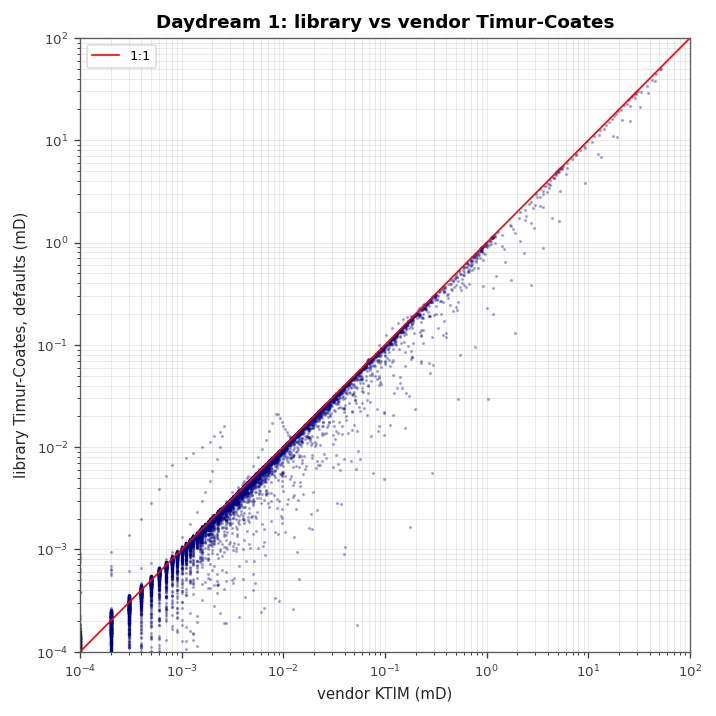

In [6]:
kc = nmr.permeability_coates(prefer_stored=False)      # library, defaults
ktim = nmr.stored_permeability["KTIM"]                 # vendor, downhole

both = np.isfinite(kc) & np.isfinite(ktim) & (kc > 0) & (ktim > 0)
resid = np.log10(kc[both]) - np.log10(ktim[both])
print("comparable samples      : %d" % both.sum())
print("median k, library/vendor: %.4f / %.4f mD" % (np.median(kc[both]), np.median(ktim[both])))
print("log10(lib/vendor)       : mean %+.3f, std %.3f decades" % (resid.mean(), resid.std()))

# Recover the vendor constant by calibrating the model to KTIM itself.
cal = nmr.calibrate_coates(nmr.depth[both], ktim[both])
print()
print("calibrate_coates vs KTIM ->", cal)

fig, ax = plt.subplots(figsize=(6, 6))
ax.loglog(ktim[both], kc[both], ".", ms=2, alpha=0.25, color="navy")
lims = (1e-4, 1e2)
ax.plot(lims, lims, "r-", lw=1, label="1:1")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("vendor KTIM (mD)")
ax.set_ylabel("library Timur-Coates, defaults (mD)")
ax.set_title("Daydream 1: library vs vendor Timur-Coates")
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.show()

### Reading the validation

The fit recovers a constant $C$ close to the textbook default of 10, with a
high log-space $R^2$ (both printed above) - the library and the vendor
implement the same model with essentially the same constants. The remaining
scatter (`RMSE_log`, in decades) is largest below 0.001 mD, where the LAS's
four-decimal export quantises `KTIM` (step 0.0001 mD), with some contribution
from rounding of the exported porosities.

Two honest caveats. First, this validates the **implementation**, not the
permeability: both curves come from the same empirical model on the same
inputs. Absolute accuracy still requires calibration to core
(`calibrate_coates` with real plug permeabilities, exactly as used here but
with core data). Second, `KSDR` cannot be reproduced the same way - it needs
T2lm from the bins this export does not carry - which is precisely why bin
data are worth requesting from the vendor.

### 4b. SDR permeability and a check against core

> **Coming with real data.** This section will recompute SDR permeability from the T2 log-mean, compare it with Timur-Coates and the vendor curves, and calibrate the constant against core permeability.
>
> It needs T2 distributions or T2 log-mean plus core permeability over the same interval. The new `phillips_cmr_log` / `phillips_cmr_core` pair supports scalar NMR-to-core calibration, but contains no T2 bins or T2 log-mean. It must not be paired with the unrelated `phillips_nmr_bins` example or Daydream to claim SDR calibration.


### 4c. NMR porosity against density-neutron porosity

> **Coming with real data.** This section will compare total NMR porosity with density-neutron porosity to expose gas, light hydrocarbons and hole effects.
>
> `pp.sample("phillips_gulfcoast_nmr")` now supplies conventional logs and scalar NMR from a separate Gulf of Mexico example. It is available for a future comparison after porosity-basis and hole-quality review. Mask -999.25 before converting fractional MPHI/MBVI to pu; do not join this well to Daydream. See the [dataset notes](https://github.com/sambalshikhar/petrophys/blob/main/src/petrophys/datasets/phillips/README.md).


## 5. Export all derived results

`NMRData.to_dataframe()` bundles the inputs, the derived curves (`MBVI`,
`SWIRR`) and every vendor and extra curve into one table for QC or hand-off.
Its `K_COATES` and `K_SDR` columns follow the same `prefer_stored=True` default
as the methods: with vendor curves loaded they repeat `KTIM` and `KSDR` (which
are also exported as `KTIM_LAS` / `KSDR_LAS`). To hand off the library's own
Timur-Coates, add the `kc` array from section 4 as a column, as below.
Bin-dependent columns (T2lm, pore size) are simply absent because the bins
are - the export never invents data.

In [7]:
out = nmr.to_dataframe()
out["K_TC_LIBRARY"] = kc   # library Timur-Coates from section 4 (same depth order)
print(textwrap.fill("exported columns: " + ", ".join(out.columns), width=100))
print("K_COATES repeats the vendor KTIM:", np.allclose(out["K_COATES"], out["KTIM"], equal_nan=True))
out.head()

exported columns: DEPTH, MPHI, MFFI, MBVI, T2CUTOFF, CMRP_3MS, CMR_TEMP, CDF, STIT, TENS, HD1_PPC1,
HD2_PPC1, BS, GR_EDTC, KSDR, KTIM, KSDR_LAS, KTIM_LAS, K_SDR, K_COATES, SWIRR, K_TC_LIBRARY
K_COATES repeats the vendor KTIM: True


,DEPTH,MPHI,MFFI,MBVI,T2CUTOFF,CMRP_3MS,CMR_TEMP,CDF,STIT,TENS,...,BS,GR_EDTC,KSDR,KTIM,KSDR_LAS,KTIM_LAS,K_SDR,K_COATES,SWIRR,K_TC_LIBRARY
0,4145.125,0.59,0.0,0.59,33.0,0.16,118.7033,-171.9887,0.0035,3490.1969,...,8.5,79.2677,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,4145.100,0.59,0.0,0.59,33.0,0.16,118.7033,-168.3570,0.0374,3530.5512,...,8.5,79.2677,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,4145.075,0.59,0.0,0.59,33.0,0.16,118.7033,-164.7253,0.0713,3570.9055,...,8.5,79.2677,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,4145.050,0.59,0.0,0.59,33.0,0.16,118.7033,-161.0936,0.1051,3611.2598,...,8.5,79.2677,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,4145.025,0.59,0.0,0.59,33.0,0.16,118.7033,-157.4619,0.1390,3651.6142,...,8.5,79.2677,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


## Pitfalls & parameter choices

- **`prefer_stored=True` is the default.** With vendor curves loaded,
  `permeability_coates()` / `permeability_sdr()` return the *stored* `KTIM` /
  `KSDR`. Pass `prefer_stored=False` when you mean "compute it yourself" -
  otherwise a comparison against the vendor compares the curve to itself.
- **Porosity units.** The container works in **pu**; `from_las` converts
  fractional (v/v) CMR curves automatically. Only worry about units when
  calling the standalone `sdr_permeability` / `coates_permeability` functions.
- **SDR needs T2lm.** No bins and no `T2LM` curve means no SDR - the method
  raises instead of guessing. Request bin exports (`T2B01...`) if you need it.
- **The cutoff is data, not folklore.** Here 33 ms comes from the file's
  `T2CUTOFF` curve (the clastic default; carbonates run ~92 ms). With only
  summary curves you also *cannot* re-split at another cutoff - `CMFF` was
  computed downhole at 33 ms.
- **Validating against `KTIM` is not core calibration.** It checks the
  implementation and constants; absolute permeability still needs plugs.
- **QC spikes before believing them.** High TCMR here is coal and washout,
  flagged by low GR and caliper-over-bit respectively.
- **This LAS is written deepest-first.** The depth index is monotonic, so it
  loads without a warning and per-sample math is safe; the first row is the
  deepest sample, so sort by depth before any step that assumes shallow-to-deep
  order.

## Recap

- A real CMR summary deliverable (Daydream 1) loads in one call:
  `NMRData.from_las(..., mphi_mnemonic="TCMR", mffi_mnemonic="CMFF")` -
  aliases, pu conversion, `MBVI = MPHI - MFFI`, cutoff, and vendor curves all
  handled.
- The porosity partition says **tight coal measures**: low total NMR porosity,
  very little free fluid and a high median Swirr; TCMR spikes are coal (low GR)
  and washout (caliper), not pay.
- Library **Timur-Coates matches the vendor's KTIM** closely, and
  `calibrate_coates` recovers a constant $C$ close to the textbook 10.
- **T2-bin products (T2 distribution, T2lm, SDR, pore size) need bin data**,
  which this summary export does not carry; the API refuses cleanly when they
  are absent, and the vendor's downhole `KSDR` shows what those bins would buy.

## Try it yourself

> **Exercise 1.** Load the shallow section
> (`pp.sample("daydream1_cmr_shallow")`, 2860-3050 m) the same way and
> compare its Swirr and `KTIM` distributions against the deep section. Which
> section has more free fluid?
>
> **Exercise 2.** Re-run `calibrate_coates` with `fit_exponents=True`. Do the
> exponents move away from $(a, b) = (4, 2)$, and what does that say about the
> parameterisation the vendor used?
>
> **Exercise 3.** `TCMR - CMRP_3MS` isolates the porosity relaxing faster than
> 3 ms (micro/clay-bound signal). `nmr.mphi` holds TCMR converted to pu;
> `CMRP_3MS` is in `nmr.extra_curves`. Check its values against its `V/V`
> label before subtracting - do they look like fractions or porosity units?
> Then plot the difference against `GR_EDTC`: does micro-porosity track
> shaliness?

## What's next

Continue with **15 - Capillary Pressure & Saturation-Height**, where the
bound/free-fluid ideas from NMR reappear as capillary equilibrium above the
free-water level, and we predict water saturation from porosity, permeability
and height.